# AI use statement
Generative AI (Claude) was used to help debug, refine and structure the Python code in this notebook. Generative AI was not used to conceive the project or to choose its aims. All modelling decisions, analyses and interpretations are the author's own work, and the author takes full responsibility for this code.

# Poisson Regression for Hospital-Acquired Infections (HAI)

Daily infection counts per ward are modelled with Poisson regression, using the patients present each day as the exposure. This:

1. describes how many hospital-acquired infections occur and what is associated with more of them (e.g. device use), using ward-level data;
2. gives the rates (incidence rate ratios, IRRs) that become the infection rules of the agent-based model (ABM);
3. through the ABM, drives the digital twin, where scenarios such as reduced device use can be tested.

## Import libraries

In [1]:
import re
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats as st
from scipy.stats import poisson, chi2
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", None)

def clean_date_axis(ax, maxticks=8):
    locator = mdates.AutoDateLocator(minticks=4, maxticks=maxticks)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

import sys, matplotlib, scipy
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | statsmodels {sm.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | statsmodels 0.15.0 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


## Load .csv 

In [2]:
import os
from pathlib import Path
DATA_DIR = str(Path("../data/synthetic_hospital").resolve())   # see data/README.md
# All tables and figures from this notebook are saved in results/poisson/
RESULTS_DIR = Path("../results/poisson").resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(RESULTS_DIR)

admissions  = pd.read_csv(f"{DATA_DIR}/admissions.csv")
patients    = pd.read_csv(f"{DATA_DIR}/patients.csv")
ward_stays  = pd.read_csv(f"{DATA_DIR}/ward_movements.csv")
infections  = pd.read_csv(f"{DATA_DIR}/infection_events.csv")
devices     = pd.read_csv(f"{DATA_DIR}/device_exposure.csv")
medications = pd.read_csv(f"{DATA_DIR}/medications.csv")

ward_stays  = ward_stays.rename(columns={"start_datetime": "ward_start_datetime", "end_datetime": "ward_end_datetime"})
devices     = devices.rename(columns={"start_datetime": "device_start_datetime", "end_datetime": "device_end_datetime"})
medications = medications.rename(columns={"start_datetime": "med_start_datetime", "end_datetime": "med_end_datetime"})

# ward_movements.csv has no patient_id, so bring it in from admissions
ward_stays = ward_stays.merge(admissions[["admission_id", "patient_id"]], on="admission_id", how="left")

# format="mixed" handles timestamps with and without microseconds
datetime_targets = [
    (ward_stays,  ["ward_start_datetime", "ward_end_datetime"]),
    (infections,  ["infection_datetime"]),
    (devices,     ["device_start_datetime", "device_end_datetime"]),
    (medications, ["med_start_datetime", "med_end_datetime"]),
    (admissions,  ["admit_datetime", "discharge_datetime"]),
]
for df, cols in datetime_targets:
    for col in cols:
        df[col] = pd.to_datetime(df[col], errors="coerce", format="mixed")

for name, df in [("admissions", admissions), ("patients", patients), ("ward_stays", ward_stays),
                 ("infections", infections), ("devices", devices), ("medications", medications)]:
    print(f"{name:12s}: {len(df):,} rows")

admissions  : 20,000 rows
patients    : 12,000 rows
ward_stays  : 33,110 rows
infections  : 2,000 rows
devices     : 10,032 rows
medications : 2,000 rows


## Attribute each infection to the ward it actually happened in

Each infection is matched to the ward stay that contains its timestamp, so that infection rates can be calculated per ward.

In [3]:
def attribute_to_ward(infections_df, ward_stays_df=ward_stays, fallback_to_last_ward=False, label="infections"):
    """Attach each infection to the ward stay whose time window contains it. Optionally fall back to the
    admission's last ward stay for infections detected after the last ward record but before discharge."""
    # Bring every ward stay belonging to the same admission alongside each infection event.
    inf_ward = infections_df.merge(ward_stays_df, on="admission_id", how="left")

    # Keep only the ward-stay row whose time window contains the infection timestamp.
    in_this_ward = (
        (inf_ward["infection_datetime"] >= inf_ward["ward_start_datetime"]) &
        (inf_ward["infection_datetime"] <=  inf_ward["ward_end_datetime"])
    )
    matched = inf_ward[in_this_ward].drop_duplicates(subset=["admission_id", "infection_id"]).copy()

    n_unmatched = len(infections_df) - matched["infection_id"].nunique()
    print(f"[{label}] attributed to exactly one ward: {matched['infection_id'].nunique():,} of {len(infections_df):,}")

    if fallback_to_last_ward and n_unmatched > 0:
        matched_ids = set(matched["infection_id"])
        unmatched_events = infections_df[~infections_df["infection_id"].isin(matched_ids)]
        last_ward = ward_stays_df.sort_values("ward_end_datetime").drop_duplicates(subset="admission_id", keep="last")
        fallback_rows = unmatched_events.merge(last_ward, on="admission_id", how="inner")
        matched = pd.concat([matched, fallback_rows], ignore_index=True)
        print(f"  -> {len(fallback_rows)} detected after the last ward record (before discharge), given to the last ward stay")
    elif n_unmatched:
        print(f"  -> {n_unmatched} infection(s) could not be matched to any ward interval")
    return matched

# Pooled analysis: all organisms, all antibiotics.
inf_ward = attribute_to_ward(infections, fallback_to_last_ward=True, label="All infections (pooled)")

[All infections (pooled)] attributed to exactly one ward: 1,688 of 2,000
  -> 312 detected after the last ward record (before discharge), given to the last ward stay


In [4]:
inf_ward.to_csv("infections_attributed_to_ward.csv", index=False)
print("Saved infections_attributed_to_ward.csv")

Saved infections_attributed_to_ward.csv


In [5]:
# How often does the last ward record end before discharge, and which wards get those infections?
last_ward = (ward_stays.sort_values(["admission_id", "ward_end_datetime"])
             .groupby("admission_id")
             .agg(last_ward_end=("ward_end_datetime", "max"), last_ward=("ward", "last"))
             .reset_index())
gap = admissions.merge(last_ward, on="admission_id")
gap["gap_hours"] = (gap["discharge_datetime"] - gap["last_ward_end"]).dt.total_seconds() / 3600
has_gap = gap[gap["gap_hours"] > 0]
print(f"Admissions with a gap before discharge: {len(has_gap):,} of {len(gap):,} ({len(has_gap)/len(gap):.1%}), "
      f"median gap {has_gap['gap_hours'].median():.1f} hours")

x = infections.merge(gap, on="admission_id")
after_last = x[x["infection_datetime"] > x["last_ward_end"]]
print(f"Infections after the last ward record: {len(after_last)} ({len(after_last)/len(infections):.1%}), "
      f"after discharge: {(after_last['infection_datetime'] > after_last['discharge_datetime']).sum()}")
print(after_last["last_ward"].value_counts().to_string())
print(f"Infections before admission: {(x['infection_datetime'] < x['admit_datetime']).sum()}, "
      f"after discharge: {(x['infection_datetime'] > x['discharge_datetime']).sum()}")

Admissions with a gap before discharge: 6,823 of 20,000 (34.1%), median gap 47.7 hours
Infections after the last ward record: 312 (15.6%), after discharge: 0
last_ward
Surgical    168
Medical     144
Infections before admission: 0, after discharge: 0


## Build the ward-day panel (the dataset the Poisson model needs)

- `n_at_risk`: patients present in the ward on that day (the patient-days exposure)
- `new_infections`: infections attributed to that ward on that day
- `device_days` / `device_utilisation`: device-days per patient-day

Each ward stay is expanded into one row per calendar day it covers, then counted.

In [6]:
def expand_stay_to_days(row):
    """Turn one ward-stay interval into one row per calendar day it overlaps."""
    first_day = row["ward_start_datetime"].floor("D")
    last_day = row["ward_end_datetime"].floor("D")
    all_days = pd.date_range(first_day, last_day, freq="D")
    return pd.DataFrame({"admission_id": row["admission_id"], "ward": row["ward"], "date": all_days})

# Expand every ward stay into daily rows, then count patients per ward-day
daily_presence = pd.concat(
    [expand_stay_to_days(row) for _, row in ward_stays.iterrows()],
    ignore_index=True
)
census = (
    daily_presence
    .groupby(["ward", "date"])
    .agg(n_at_risk=("admission_id", "nunique"))
    .reset_index()
)

print(f"Ward-day panel scaffold: {len(census):,} rows across "
      f"{census['ward'].nunique()} wards and {census['date'].nunique()} calendar days")
census.head()

Ward-day panel scaffold: 2,936 rows across 4 wards and 737 calendar days


,ward,date,n_at_risk
0,ED,2023-01-01,24
1,ED,2023-01-02,38
2,ED,2023-01-03,48
3,ED,2023-01-04,48
4,ED,2023-01-05,47


In [7]:
# Device episodes per admission, and whether admissions with both devices had them at the same time
dev = pd.read_csv(f"{DATA_DIR}/device_exposure.csv", parse_dates=["start_datetime", "end_datetime"])

per_adm = (admissions[["admission_id"]]
           .merge(dev.groupby("admission_id").size().rename("n_devices"), on="admission_id", how="left")
           .fillna({"n_devices": 0}))
types = dev.groupby("admission_id")["device_type"].apply(lambda s: " + ".join(sorted(s)))
per_adm["combo"] = per_adm["admission_id"].map(types).fillna("No device")
print(dev["device_type"].value_counts().to_string())
print()
print(per_adm["combo"].value_counts().to_string())

both = dev[dev["admission_id"].isin(per_adm.loc[per_adm["n_devices"] == 2, "admission_id"])]
cath = both[both["device_type"] == "Urinary Catheter"].set_index("admission_id")
line = both[both["device_type"] == "Central Line"].set_index("admission_id")
pair = cath.join(line, lsuffix="_cath", rsuffix="_line")
same_time = (pair["start_datetime_cath"] < pair["end_datetime_line"]) & (pair["start_datetime_line"] < pair["end_datetime_cath"])
print(f"\nAdmissions with both devices: {len(pair):,}, both in place at the same time: {same_time.sum():,}")

device_type
Urinary Catheter    6063
Central Line        3969

combo
No device                          11194
Urinary Catheter                    4837
Central Line                        2743
Central Line + Urinary Catheter     1226

Admissions with both devices: 1,226, both in place at the same time: 976


## Sensitivity analysis: infections after the last ward record

In [8]:
# Sensitivity analysis for infections detected after the last ward record (Tables 4.2 and 4.5)
#   A. as built   B. those infections removed   C. last ward stay extended to discharge

s_adm = pd.read_csv(f"{DATA_DIR}/admissions.csv",       parse_dates=["admit_datetime", "discharge_datetime"])
s_wrd = pd.read_csv(f"{DATA_DIR}/ward_movements.csv",   parse_dates=["start_datetime", "end_datetime"])
s_inf = pd.read_csv(f"{DATA_DIR}/infection_events.csv", parse_dates=["infection_datetime"])
s_dev = pd.read_csv(f"{DATA_DIR}/device_exposure.csv",  parse_dates=["start_datetime", "end_datetime"])
s_wrd = s_wrd.rename(columns={"start_datetime": "w_start", "end_datetime": "w_end"})
s_dev = s_dev.rename(columns={"start_datetime": "d_start", "end_datetime": "d_end"})

def days_between(start, end):
    """One row per calendar day touched by [start, end]."""
    first, last = start.dt.floor("D"), end.dt.floor("D")
    n = (last - first).dt.days + 1
    idx = np.repeat(np.arange(len(start)), n)
    offs = np.concatenate([np.arange(k) for k in n])
    return idx, first.values[idx] + pd.to_timedelta(offs, unit="D").values

def attribute(inf, wrd):
    """Same rule as attribute_to_ward(): ward stay containing the infection, else the last ward stay."""
    m = inf.merge(wrd, on="admission_id")
    inside = m[(m["infection_datetime"] >= m["w_start"]) & (m["infection_datetime"] <= m["w_end"])]
    inside = inside.drop_duplicates("infection_id").assign(gap=False)
    rest = inf[~inf["infection_id"].isin(inside["infection_id"])]
    last = wrd.sort_values("w_end").drop_duplicates("admission_id", keep="last")
    gap = rest.merge(last, on="admission_id").assign(gap=True)
    return pd.concat([inside, gap], ignore_index=True)

def build(wrd, inf_att):
    """Same steps as the ward-day panel: census, device-days and infections per ward-day."""
    i, d = days_between(wrd["w_start"], wrd["w_end"])
    pres = pd.DataFrame({"admission_id": wrd["admission_id"].values[i], "ward": wrd["ward"].values[i], "date": d})
    census = pres.groupby(["ward", "date"])["admission_id"].nunique().rename("n_at_risk").reset_index()

    dw = s_dev.merge(wrd, on="admission_id")
    dw["os"] = dw[["d_start", "w_start"]].max(axis=1)
    dw["oe"] = dw[["d_end", "w_end"]].min(axis=1)
    dw = dw[dw["os"] < dw["oe"]].reset_index(drop=True)
    i, d = days_between(dw["os"], dw["oe"])
    dd = pd.DataFrame({"ward": dw["ward"].values[i], "date": d}).groupby(["ward", "date"]).size().rename("device_days").reset_index()

    inf = inf_att.assign(date=inf_att["infection_datetime"].dt.floor("D"))
    ni = inf.groupby(["ward", "date"]).size().rename("new_infections").reset_index()

    p = census.merge(ni, on=["ward", "date"], how="left").merge(dd, on=["ward", "date"], how="left")
    p[["new_infections", "device_days"]] = p[["new_infections", "device_days"]].fillna(0).astype(int)
    p["device_utilisation"] = (p["device_days"] / p["n_at_risk"]).round(4)
    return p

# ---- Scenario panels ----
att_A = attribute(s_inf, s_wrd)
print(f"Infections: {len(att_A):,}  (inside a ward stay: {(~att_A['gap']).sum():,}, after last ward record: {att_A['gap'].sum():,})")

panel_A = build(s_wrd, att_A)                      # A. as built now
panel_B = build(s_wrd, att_A[~att_A["gap"]])       # B. gap infections removed

s_wrd_C = s_wrd.merge(s_adm[["admission_id", "discharge_datetime"]], on="admission_id")
is_last = s_wrd_C.index.isin(s_wrd_C.sort_values("w_end").drop_duplicates("admission_id", keep="last").index)
s_wrd_C.loc[is_last, "w_end"] = s_wrd_C.loc[is_last, ["w_end", "discharge_datetime"]].max(axis=1)
s_wrd_C = s_wrd_C.drop(columns="discharge_datetime")
att_C = attribute(s_inf, s_wrd_C)
panel_C = build(s_wrd_C, att_C)                    # C. last ward stay extended to discharge
print(f"Scenario C: infections still after the (extended) last ward stay: {att_C['gap'].sum()}  (should be 0)")

for name, p in [("A", panel_A), ("B", panel_B), ("C", panel_C)]:
    print(f"Panel {name}: {len(p):,} ward-days, {p['new_infections'].sum():,} infections, "
          f"{p['n_at_risk'].sum():,} patient-days")

# ---- 1. Crude rates per 1,000 patient-days ----
def crude(p):
    g = p.groupby("ward")[["new_infections", "n_at_risk"]].sum()
    return (1000 * g["new_infections"] / g["n_at_risk"]).round(1)

crude_tbl = pd.DataFrame({"A. As built": crude(panel_A),
                          "B. Gap infections out": crude(panel_B),
                          "C. Gap days in": crude(panel_C)})
print("\n=== Crude infections per 1,000 patient-days ===")
print(crude_tbl.to_string())

# ---- 2. Model 3 on the same training days for all scenarios (first 70% of dates) ----
all_dates = sorted(panel_A["date"].unique())
train_dates = set(all_dates[: int(len(all_dates) * 0.7)])

def fit_m3(p):
    tr = p[p["date"].isin(train_dates)]
    m = smf.glm("new_infections ~ 1 + device_utilisation + C(ward)", data=tr,
                family=sm.families.Poisson(), offset=np.log(tr["n_at_risk"])).fit()
    ci = np.exp(m.conf_int())
    out = pd.DataFrame({"IRR": np.exp(m.params), "CI_low": ci[0], "CI_high": ci[1], "p": m.pvalues})
    out.index = out.index.str.replace("C(ward)[T.", "", regex=False).str.replace("]", "", regex=False)
    disp = m.pearson_chi2 / m.df_resid
    return out.drop(index="Intercept").round(3), disp, len(tr)

print("\n=== Model 3 IRRs (reference ward = ED), fitted on training days ===")
for name, p in [("A. As built", panel_A), ("B. Gap infections out", panel_B), ("C. Gap days in", panel_C)]:
    tbl, disp, n = fit_m3(p)
    print(f"\n{name}   (training ward-days = {n:,}, dispersion = {disp:.2f})")
    print(tbl.to_string())

Infections: 2,000  (inside a ward stay: 1,688, after last ward record: 312)


Scenario C: infections still after the (extended) last ward stay: 0  (should be 0)
Panel A: 2,936 ward-days, 2,000 infections, 72,830 patient-days
Panel B: 2,936 ward-days, 1,688 infections, 72,830 patient-days
Panel C: 2,955 ward-days, 2,000 infections, 92,959 patient-days

=== Crude infections per 1,000 patient-days ===
          A. As built  B. Gap infections out  C. Gap days in
ward                                                        
ED               28.0                   28.0            28.0
ICU              14.8                   14.8            14.8
Medical          26.1                   14.6            14.5
Surgical         31.0                   17.2            17.0

=== Model 3 IRRs (reference ward = ED), fitted on training days ===

A. As built   (training ward-days = 2,057, dispersion = 0.96)
                      IRR  CI_low  CI_high      p
ICU                 0.597   0.442    0.806  0.001
Medical             0.955   0.824    1.106  0.537
Surgical            1.150   

In [9]:
# Device-days: a device only counts for a ward-day while the patient is in that ward, so each device
# interval is clipped to the overlapping ward stay and then expanded into daily rows.
dev_ward = devices.merge(ward_stays, on="admission_id", how="left")

overlap_start = dev_ward[["device_start_datetime", "ward_start_datetime"]].max(axis=1)
overlap_end   = dev_ward[["device_end_datetime",   "ward_end_datetime"]].min(axis=1)
dev_ward = dev_ward.assign(overlap_start=overlap_start, overlap_end=overlap_end)

# Keep positive-length overlaps only
dev_ward = dev_ward[dev_ward["overlap_start"] < dev_ward["overlap_end"]].copy()

def expand_overlap_to_days(row):
    first_day = row["overlap_start"].floor("D")
    last_day = row["overlap_end"].floor("D")
    all_days = pd.date_range(first_day, last_day, freq="D")
    return pd.DataFrame({"admission_id": row["admission_id"], "ward": row["ward"],
                          "device_type": row["device_type"], "date": all_days})

if len(dev_ward) > 0:
    device_daily = pd.concat(
        [expand_overlap_to_days(row) for _, row in dev_ward.iterrows()],
        ignore_index=True
    )
    # Pooled device-days (any device type)
    device_days = (
        device_daily.groupby(["ward", "date"]).agg(device_days=("admission_id", "count")).reset_index()
    )
    # The same, split by device type
    device_days_by_type = (
        device_daily.groupby(["ward", "date", "device_type"]).agg(n=("admission_id", "count"))
        .unstack("device_type", fill_value=0)
    )
    device_days_by_type.columns = [f"device_days_{c.strip().lower().replace(' ', '_')}"
                                    for c in device_days_by_type.columns.get_level_values(1)]
    device_days_by_type = device_days_by_type.reset_index()
else:
    device_days = pd.DataFrame(columns=["ward", "date", "device_days"])
    device_days_by_type = pd.DataFrame(columns=["ward", "date"])

type_cols = [c for c in device_days_by_type.columns if c.startswith("device_days_")]
print(f"Device types found in this data: {[c.replace('device_days_', '') for c in type_cols]}")

def build_panel(inf_ward_subset, label="panel"):
    """Ward-day panel for a set of ward-attributed infections (census and device-days are shared)."""
    inf = inf_ward_subset.copy()
    inf["date"] = inf["infection_datetime"].dt.floor("D")
    new_infections = inf.groupby(["ward", "date"]).size().reset_index(name="new_infections")

    p = census.merge(new_infections, on=["ward", "date"], how="left")
    p = p.merge(device_days, on=["ward", "date"], how="left")
    p = p.merge(device_days_by_type, on=["ward", "date"], how="left")
    p["new_infections"] = p["new_infections"].fillna(0).astype(int)
    p["device_days"] = p["device_days"].fillna(0).astype(int)
    for c in type_cols:
        p[c] = p[c].fillna(0).astype(int)

    # device_utilisation = device-days / patient-days
    p["device_utilisation"] = (p["device_days"] / p["n_at_risk"]).round(4)
    for c in type_cols:
        p[c.replace("device_days_", "device_utilisation_")] = (p[c] / p["n_at_risk"]).round(4)

    p = p.sort_values(["ward", "date"]).reset_index(drop=True)
    print(f"[{label}] panel: {p.shape[0]:,} rows, {p['new_infections'].sum():,} total infections in this panel")
    return p

panel = build_panel(inf_ward, label="Pooled")
panel.to_csv("ward_day_panel.csv", index=False)

print(f"\nFinal pooled ward-day panel: {panel.shape[0]:,} rows, {panel.shape[1]} columns  (saved to ward_day_panel.csv)")
panel.head(10)

Device types found in this data: ['central_line', 'urinary_catheter']
[Pooled] panel: 2,936 rows, 2,000 total infections in this panel

Final pooled ward-day panel: 2,936 rows, 10 columns  (saved to ward_day_panel.csv)


,ward,date,n_at_risk,new_infections,device_days,device_days_central_line,device_days_urinary_catheter,device_utilisation,device_utilisation_central_line,device_utilisation_urinary_catheter
0,ED,2023-01-01,24,0,5,1,4,0.2083,0.0417,0.1667
1,ED,2023-01-02,38,2,10,4,6,0.2632,0.1053,0.1579
2,ED,2023-01-03,48,1,18,8,10,0.3750,0.1667,0.2083
3,ED,2023-01-04,48,0,21,10,11,0.4375,0.2083,0.2292
4,ED,2023-01-05,47,3,17,9,8,0.3617,0.1915,0.1702
5,ED,2023-01-06,63,1,23,9,14,0.3651,0.1429,0.2222
6,ED,2023-01-07,63,1,20,7,13,0.3175,0.1111,0.2063
7,ED,2023-01-08,58,1,12,3,9,0.2069,0.0517,0.1552
8,ED,2023-01-09,67,2,18,8,10,0.2687,0.1194,0.1493
9,ED,2023-01-10,68,1,11,6,5,0.1618,0.0882,0.0735


## Exploratory plots


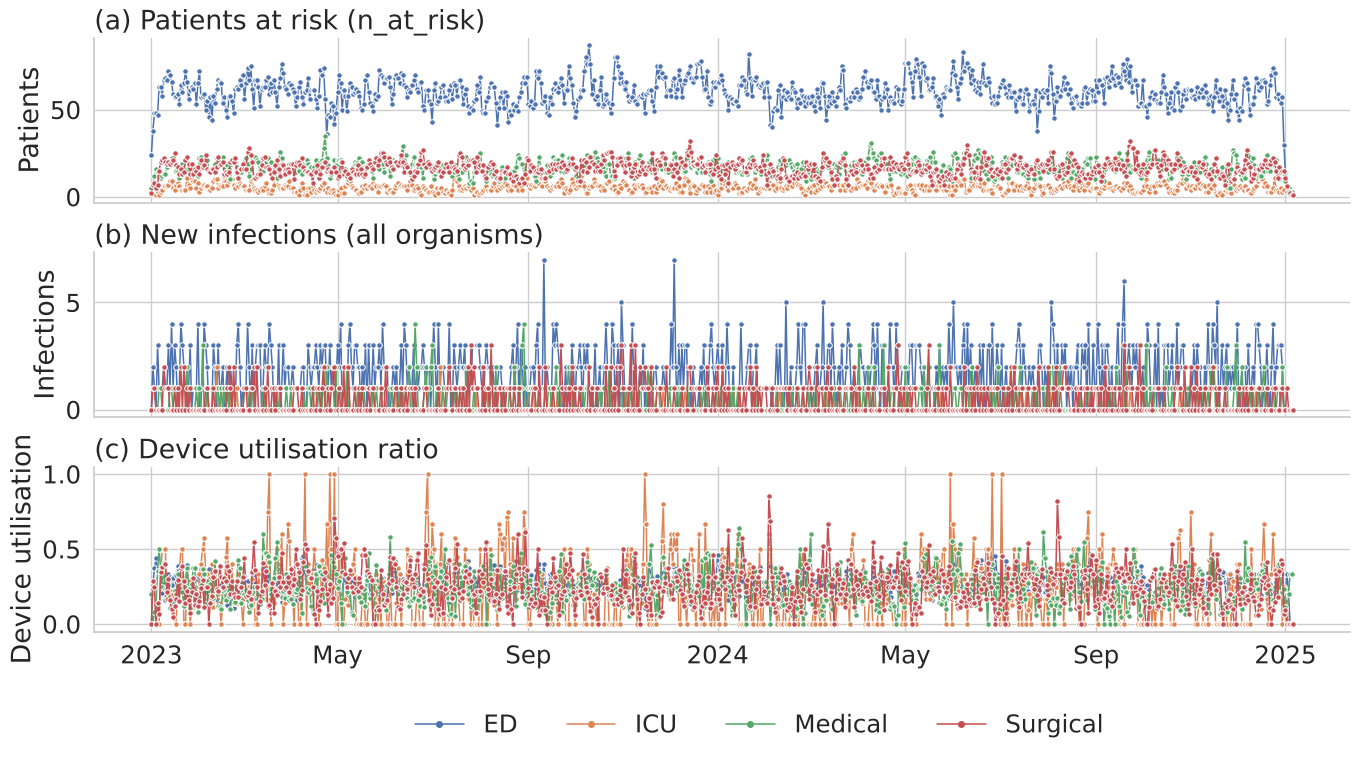

In [10]:
plot_df = panel.melt(
    id_vars=["ward", "date"],
    value_vars=["n_at_risk", "new_infections", "device_utilisation"],
    var_name="metric", value_name="value"
)
# Three stacked subplots (a)-(c), one per quantity, with one legend below
with sns.plotting_context("notebook", font_scale=1.6):
    g = sns.relplot(
        data=plot_df, x="date", y="value", hue="ward", row="metric",
        kind="line", marker="o", markersize=4, linewidth=1.1,
        facet_kws={"sharey": False}, height=2.5, aspect=5.6
    )
    titles = ["(a) Patients at risk (n_at_risk)", "(b) New infections (all organisms)", "(c) Device utilisation ratio"]
    ylabels = ["Patients", "Infections", "Device utilisation"]
    g.set_titles(row_template="", col_template="")
    for ax, title, ylab in zip(g.axes.flat, titles, ylabels):
        ax.set_title(title, loc="left")
        ax.set_ylabel(ylab)
        clean_date_axis(ax)
    g.set_xlabels("")
    sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, -0.04), ncol=4, title=None, frameon=False)
    g.figure.subplots_adjust(hspace=0.3)
    g.savefig("ward_day_metrics.png", dpi=200, bbox_inches="tight")
    plt.show()

## Fit the Poisson model

`new_infections` is a count (0, 1, 2, ...), so a Poisson regression is used (`statsmodels`). The model estimates the infection rate per patient-day, with `log(n_at_risk)` as the offset, and lets it depend on device use and ward.

**IRR (incidence rate ratio):** IRR = 1 means no effect, IRR = 2 means the rate doubles and IRR = 0.5 means it halves.

In [11]:
def sig_stars(p_value):
    """p-value -> significance stars."""
    if p_value < 0.001:
        return "***"
    elif p_value < 0.01:
        return "**"
    elif p_value < 0.05:
        return "*"
    else:
        return ""

def format_p(p_value):
    """Print '<0.001' instead of 0.000."""
    return "<0.001" if p_value < 0.001 else f"{p_value:.3f}"

def clean_ward_name(term):
    """'C(ward)[T.ICU]' -> 'ICU'."""
    match = re.match(r"C\(\w+\)\[T\.(.+)\]", term)
    return match.group(1) if match else term

## Split the data into train / validation / test

1. **Train**: the first 70% of days; the models only learn from this period.
2. **Validation**: the next 15%; used to choose between the three models.
3. **Test**: the last 15%; used once at the end to report performance on unseen days.

The split is by date, not by row, so that neighbouring days do not leak information between the periods.

In [12]:
def split_train_val_test(panel_df, train_frac=0.7, val_frac=0.15, label="panel"):
    """Split a ward-day panel into train / validation / test by calendar date."""
    all_dates = sorted(panel_df["date"].unique())
    n_dates = len(all_dates)
    n_train = int(n_dates * train_frac)
    n_val = int(n_dates * val_frac)

    train_dates = all_dates[:n_train]
    val_dates = all_dates[n_train : n_train + n_val]
    test_dates = all_dates[n_train + n_val :]

    train_df = panel_df[panel_df["date"].isin(train_dates)].reset_index(drop=True)
    val_df = panel_df[panel_df["date"].isin(val_dates)].reset_index(drop=True)
    test_df = panel_df[panel_df["date"].isin(test_dates)].reset_index(drop=True)

    print(f"[{label}] {len(train_dates)} train days ({len(train_df)} ward-days), "
          f"{len(val_dates)} validation days ({len(val_df)} ward-days), "
          f"{len(test_dates)} test days ({len(test_df)} ward-days)")
    return train_df, val_df, test_df

train_panel, val_panel, test_panel = split_train_val_test(panel, label="Pooled")

[Pooled] 515 train days (2057 ward-days), 110 validation days (440 ward-days), 112 test days (439 ward-days)


## Turn a fitted model into a results table

Coefficient, standard error, p-value and IRR with 95% confidence interval for each predictor.

In [13]:
def summarise_model(name, fitted_result, verbose=True):
    """Results table (coef, SE, z, p, IRR and 95% CI) and fit statistics; also keeps the fitted model."""
    coefficients = fitted_result.params
    std_errors = fitted_result.bse
    z_scores = fitted_result.tvalues
    p_values = fitted_result.pvalues
    conf_int = fitted_result.conf_int()
    conf_int.columns = ["ci_low", "ci_high"]

    term_names = [clean_ward_name(t) for t in coefficients.index]

    results_table = pd.DataFrame({
        "term": term_names,
        "coef": coefficients.values,
        "se": std_errors.values,
        "z": z_scores.values,
        "p_value": p_values.values,
        "sig": [sig_stars(p) for p in p_values.values],
        "p_display": [format_p(p) for p in p_values.values],
        "IRR": np.exp(coefficients.values),
        "IRR_2.5%": np.exp(conf_int["ci_low"].values),
        "IRR_97.5%": np.exp(conf_int["ci_high"].values),
    })

    # Dispersion = Pearson chi-square / residual df (about 1 for Poisson data)
    dispersion = fitted_result.pearson_chi2 / fitted_result.df_resid

    if verbose:
        print(f"\n=== {name} ===")
        print(results_table[["term", "coef", "se", "z", "p_display", "sig", "IRR", "IRR_2.5%", "IRR_97.5%"]].to_string(index=False))
        print(f"AIC = {fitted_result.aic:.2f}   deviance = {fitted_result.deviance:.2f}   "
              f"dispersion = {dispersion:.2f}")

    return dict(name=name, aic=fitted_result.aic, deviance=fitted_result.deviance,
                df_resid=fitted_result.df_resid, dispersion=dispersion, table=results_table,
                model=fitted_result)

## Fit three models, on the training data only

- **Model 1**: baseline only
- **Model 2**: + device utilisation
- **Model 3**: + ward (ED as the reference)

In [14]:
def fit_three_models(panel_df, label="panel", verbose=True):
    """Fit Models 1-3 on the given (training) panel. log(n_at_risk) is the offset, so the models estimate rates."""
    offset = np.log(panel_df["n_at_risk"])

    # ---- Model 1: baseline only ----
    model_1 = smf.glm("new_infections ~ 1", data=panel_df,
                       family=sm.families.Poisson(), offset=offset).fit()
    res1 = summarise_model(f"[{label}] Model 1: baseline only", model_1, verbose)

    # ---- Model 2: + device utilisation ----
    model_2 = smf.glm("new_infections ~ 1 + device_utilisation", data=panel_df,
                       family=sm.families.Poisson(), offset=offset).fit()
    res2 = summarise_model(f"[{label}] Model 2: + device utilisation", model_2, verbose)

    # ---- Model 3: + ward ----
    # C(ward): ward as a categorical variable (ED is the reference)
    model_3 = smf.glm("new_infections ~ 1 + device_utilisation + C(ward)", data=panel_df,
                       family=sm.families.Poisson(), offset=offset).fit()
    res3 = summarise_model(f"[{label}] Model 3: + ward", model_3, verbose)

    comparison = pd.DataFrame({
        "model": [res1["name"], res2["name"], res3["name"]],
        "AIC": [res1["aic"], res2["aic"], res3["aic"]],
        "dispersion": [res1["dispersion"], res2["dispersion"], res3["dispersion"]],
    })

    if verbose:
        print(f"\n[{label}] AIC comparison (measured on the TRAINING data):")
        print(comparison.to_string(index=False))

    return dict(res1=res1, res2=res2, res3=res3, comparison=comparison)

fit_results = fit_three_models(train_panel, label="Pooled (train)")
comparison = fit_results["comparison"]


=== [Pooled (train)] Model 1: baseline only ===
     term      coef       se           z p_display sig      IRR  IRR_2.5%  IRR_97.5%
Intercept -3.609165 0.026832 -134.511028    <0.001 *** 0.027074  0.025687   0.028536
AIC = 3784.19   deviance = 1786.28   dispersion = 0.90

=== [Pooled (train)] Model 2: + device utilisation ===
              term      coef       se          z p_display sig      IRR  IRR_2.5%  IRR_97.5%
         Intercept -3.836794 0.079013 -48.558992    <0.001 *** 0.021563  0.018469   0.025174
device_utilisation  0.854776 0.274933   3.109037     0.002  ** 2.350849  1.371518   4.029470
AIC = 3776.67   deviance = 1776.76   dispersion = 0.90

=== [Pooled (train)] Model 3: + ward ===
              term      coef       se          z p_display sig      IRR  IRR_2.5%  IRR_97.5%
         Intercept -3.822041 0.085523 -44.690339    <0.001 *** 0.021883  0.018506   0.025877
               ICU -0.515411 0.153070  -3.367156    <0.001 *** 0.597255  0.442452   0.806220
           Medi

## Pick the best model, using the validation set

AIC only measures fit to the training data. The model with the lowest RMSE on the validation days is kept. Errors are calculated from the continuous expected counts (`predicted`); the rounded values (`predicted_infections`) are only used in plots.

In [15]:
def attach_predictions(df, fitted_entry):
    """Add the expected count ('predicted', used for all error metrics) and its rounded value
    ('predicted_infections', used in plots)."""
    result_df = df.copy()
    offset = np.log(result_df["n_at_risk"])
    result_df["predicted"] = fitted_entry["model"].predict(result_df, offset=offset).to_numpy()
    result_df["predicted_infections"] = result_df["predicted"].round().astype(int)
    return result_df

def evaluate_on(fitted_entry, df, label, split_name):
    """MAE and RMSE of a model's predictions on a panel."""
    df_pred = attach_predictions(df, fitted_entry)
    mae = (df_pred["new_infections"] - df_pred["predicted"]).abs().mean()
    rmse = np.sqrt(((df_pred["new_infections"] - df_pred["predicted"]) ** 2).mean())
    print(f"[{label}] {fitted_entry['name']} on {split_name}: MAE = {mae:.3f}, RMSE = {rmse:.3f} (n = {len(df_pred)})")
    return dict(split=split_name, model=fitted_entry["name"], mae=mae, rmse=rmse, n=len(df_pred))

# Score all three models on the validation set.
val_scores = [evaluate_on(fit_results[key], val_panel, "Pooled", "validation") for key in ["res1", "res2", "res3"]]
val_scores_df = pd.DataFrame(val_scores)
print("\nValidation-set accuracy, all three models:")
print(val_scores_df.to_string(index=False))

# Pick the model with the lowest validation RMSE
comparison = comparison.merge(
    val_scores_df[["model", "mae", "rmse"]].rename(columns={"mae": "val_MAE", "rmse": "val_RMSE"}),
    on="model"
)
best_model_name = val_scores_df.loc[val_scores_df["rmse"].idxmin(), "model"]
best = next(fit_results[key] for key in ["res1", "res2", "res3"] if fit_results[key]["name"] == best_model_name)

print(f"\nBest model (lowest validation RMSE): {best['name']}")
# Test error of every model, reported in Table 4.3 (the choice above uses validation only)
test_scores = pd.DataFrame([evaluate_on(fit_results[key], test_panel, "Pooled", "test") for key in ["res1", "res2", "res3"]])
comparison = comparison.merge(test_scores[["model", "mae", "rmse"]].rename(columns={"mae": "test_MAE", "rmse": "test_RMSE"}),
                              on="model")
comparison

[Pooled] [Pooled (train)] Model 1: baseline only on validation: MAE = 0.616, RMSE = 0.817 (n = 440)
[Pooled] [Pooled (train)] Model 2: + device utilisation on validation: MAE = 0.612, RMSE = 0.811 (n = 440)
[Pooled] [Pooled (train)] Model 3: + ward on validation: MAE = 0.601, RMSE = 0.810 (n = 440)

Validation-set accuracy, all three models:
     split                                          model      mae     rmse   n
validation        [Pooled (train)] Model 1: baseline only 0.616334 0.816877 440
validation [Pooled (train)] Model 2: + device utilisation 0.612159 0.811462 440
validation               [Pooled (train)] Model 3: + ward 0.600772 0.809893 440

Best model (lowest validation RMSE): [Pooled (train)] Model 3: + ward
[Pooled] [Pooled (train)] Model 1: baseline only on test: MAE = 0.588, RMSE = 0.824 (n = 439)
[Pooled] [Pooled (train)] Model 2: + device utilisation on test: MAE = 0.582, RMSE = 0.822 (n = 439)
[Pooled] [Pooled (train)] Model 3: + ward on test: MAE = 0.572, RMSE =

,model,AIC,dispersion,val_MAE,val_RMSE,test_MAE,test_RMSE
0,[Pooled (train)] Model 1: baseline only,3784.188286,0.901214,0.616334,0.816877,0.587503,0.824432
1,[Pooled (train)] Model 2: + device utilisation,3776.665047,0.904776,0.612159,0.811462,0.581931,0.821813
2,[Pooled (train)] Model 3: + ward,3762.930596,0.959277,0.600772,0.809893,0.572329,0.820282


## Save the model comparison and coefficients

In [16]:
comparison.to_csv("model_comparison.csv", index=False)
best["table"].to_csv("best_model_coefficients.csv", index=False)
fit_results["res1"]["table"].to_csv("model1_baseline_coefficients.csv", index=False)
fit_results["res2"]["table"].to_csv("model2_device_coefficients.csv", index=False)
fit_results["res3"]["table"].to_csv("model3_ward_coefficients.csv", index=False)

print("Saved: model_comparison.csv, best_model_coefficients.csv, and one CSV per model")
best["table"]

Saved: model_comparison.csv, best_model_coefficients.csv, and one CSV per model


,term,coef,se,z,p_value,sig,p_display,IRR,IRR_2.5%,IRR_97.5%
0,Intercept,-3.822041,0.085523,-44.690339,0.000000,***,<0.001,0.021883,0.018506,0.025877
1,ICU,-0.515411,0.153070,-3.367156,0.000759,***,<0.001,0.597255,0.442452,0.806220
2,Medical,-0.046302,0.074910,-0.618100,0.536510,,0.537,0.954754,0.824381,1.105745
3,Surgical,0.140098,0.070286,1.993265,0.046232,*,0.046,1.150387,1.002343,1.320296
4,device_utilisation,0.816993,0.284115,2.875575,0.004033,**,0.004,2.263682,1.297110,3.950520


## Check the Poisson assumption: does mean = variance?

The dispersion statistic (Pearson chi-square / residual degrees of freedom) should be close to 1. If it fell outside 0.8-1.2, the standard errors would be widened by √dispersion (a quasi-Poisson correction).

In [17]:
dispersion = best["dispersion"]
print(f"Dispersion for the chosen model ({best['name']}), measured on training data: {dispersion:.2f}")

if not (0.8 <= dispersion <= 1.2):
    print("Outside 0.8-1.2, so the standard errors are widened (quasi-Poisson):")
    adjusted = best["table"].copy()
    adjusted["se"] = adjusted["se"] * np.sqrt(dispersion)
    adjusted["z"] = adjusted["coef"] / adjusted["se"]
    adjusted["p_value"] = 2 * (1 - st.norm.cdf(np.abs(adjusted["z"])))
    adjusted["sig"] = [sig_stars(p) for p in adjusted["p_value"]]
    adjusted["p_display"] = [format_p(p) for p in adjusted["p_value"]]
    adjusted["IRR_2.5%"] = np.exp(adjusted["coef"] - 1.96 * adjusted["se"])
    adjusted["IRR_97.5%"] = np.exp(adjusted["coef"] + 1.96 * adjusted["se"])
    adjusted.to_csv("best_model_coefficients_quasipoisson.csv", index=False)
    print(adjusted.to_string(index=False))
else:
    print("Within 0.8-1.2, so no quasi-Poisson correction is needed.")

Dispersion for the chosen model ([Pooled (train)] Model 3: + ward), measured on training data: 0.96
Within 0.8-1.2, so no quasi-Poisson correction is needed.


## Predicted vs actual on the test set

The test days have not been used for fitting or choosing the model. The noise floor is the mean absolute error that even a perfect Poisson forecast would make, because each observed count is a random draw around its rate.

ward       date  new_infections  predicted  predicted_infections
  ED 2024-09-17               1   1.653063                     2
  ED 2024-09-18               4   2.084289                     2
  ED 2024-09-19               6   1.846789                     2
  ED 2024-09-20               1   1.848456                     2
  ED 2024-09-21               2   2.170461                     2
  ED 2024-09-22               3   1.739011                     2
  ED 2024-09-23               2   2.040795                     2
  ED 2024-09-24               1   1.700709                     2
  ED 2024-09-25               3   1.826091                     2
  ED 2024-09-26               2   1.826091                     2


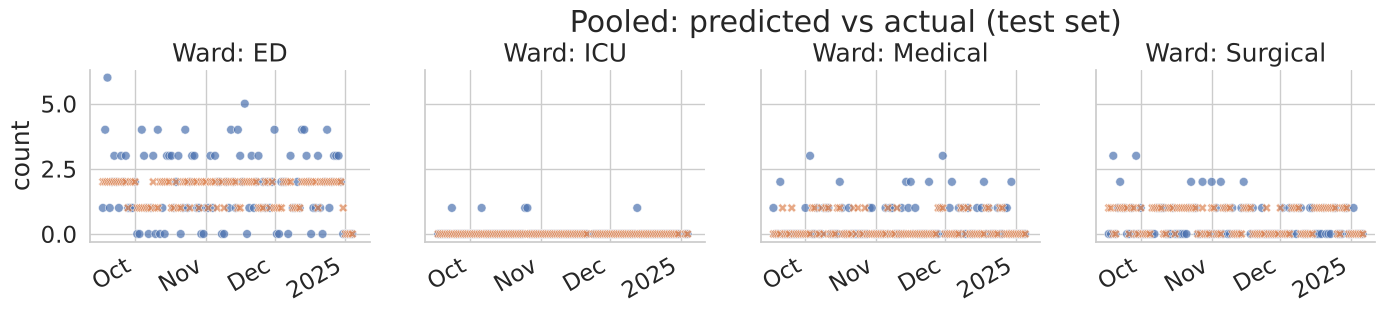

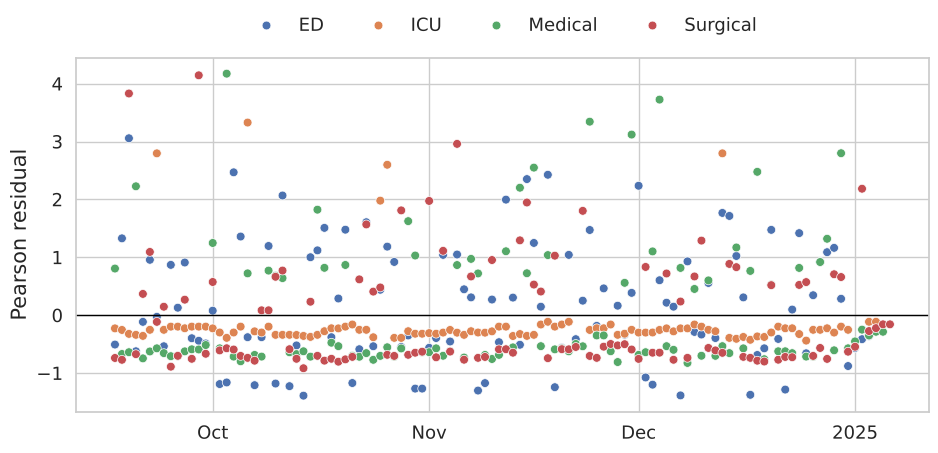

[Pooled] [Pooled (train)] Model 3: + ward on train: MAE = 0.578, RMSE = 0.793 (n = 2057)
[Pooled] [Pooled (train)] Model 3: + ward on validation: MAE = 0.601, RMSE = 0.810 (n = 440)
[Pooled] [Pooled (train)] Model 3: + ward on test: MAE = 0.572, RMSE = 0.820 (n = 439)

Test noise floor MAE: 0.564 (model MAE 0.572)
Test ward-days within one infection: 84.3%
Pearson residuals: mean 0.01, SD 0.97, |r| > 2: 5.2%
          new_infections  predicted
ward                               
ED                   194      170.5
ICU                    5        8.7
Medical               49       45.3
Surgical              52       55.4


In [18]:
def plot_predicted_vs_actual(df_with_predictions, label, filename, show_legend=True):
    """Actual vs rounded predicted infections over time, one panel per ward (legend below the plots)."""
    plot_data = df_with_predictions.melt(
        id_vars=["ward", "date"], value_vars=["new_infections", "predicted_infections"],
        var_name="series", value_name="count"
    )
    with sns.plotting_context("notebook", font_scale=1.5):
        fig = sns.relplot(
            data=plot_data, x="date", y="count", hue="series", style="series", col="ward",
            col_order=["ED", "ICU", "Medical", "Surgical"], kind="scatter", col_wrap=4,
            height=3.2, aspect=1.1, alpha=0.7, s=40
        )
        fig.set_titles("Ward: {col_name}")
        fig.set_xlabels("")
        if fig._legend is not None:
            fig._legend.set_title("")
            for t, new_label in zip(fig._legend.texts, ["Actual", "Predicted (rounded)"]):
                t.set_text(new_label)
            sns.move_legend(fig, "lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, title=None, frameon=False)
            if not show_legend:
                fig._legend.remove()
        for ax in fig.axes.flat:
            clean_date_axis(ax)
            plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        fig.figure.suptitle(f"{label}: predicted vs actual (test set)", y=1.02)
        fig.figure.subplots_adjust(wspace=0.2, hspace=0.35)
        fig.savefig(f"{filename}_predicted_vs_actual.png", dpi=200, bbox_inches="tight")
        plt.show()


def plot_residuals(df_with_predictions, filename):
    """Pearson residual = (actual - predicted) / sqrt(predicted), over the test period."""
    df_plot = df_with_predictions.copy()
    df_plot["pearson_resid"] = (df_plot["new_infections"] - df_plot["predicted"]) / np.sqrt(df_plot["predicted"])
    with plt.rc_context(BIG_FONTS):
        fig, ax = plt.subplots(figsize=(11, 4.6))
        sns.scatterplot(data=df_plot, x="date", y="pearson_resid", hue="ward",
                        hue_order=["ED", "ICU", "Medical", "Surgical"], ax=ax, s=40)
        ax.axhline(0, color="black", linewidth=1)
        ax.set_ylabel("Pearson residual"); ax.set_xlabel("")
        ax.legend(title="", ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False)
        clean_date_axis(ax)
        fig.savefig(f"{filename}_residuals.png", dpi=150, bbox_inches="tight")
        plt.show()
    return df_plot


def noise_floor(predicted):
    """Expected MAE of a perfect Poisson forecast with these expected counts."""
    k = np.arange(0, 40)
    return np.mean([np.sum(poisson.pmf(k, mu) * np.abs(k - mu)) for mu in predicted])


# Larger fonts so these figures stay readable at page width in the thesis
BIG_FONTS = {"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
             "ytick.labelsize": 13, "legend.fontsize": 13, "font.family": "DejaVu Sans", "axes.titleweight": "normal"}

train_with_predictions = attach_predictions(train_panel, best)
val_with_predictions = attach_predictions(val_panel, best)
test_with_predictions = attach_predictions(test_panel, best)

print(test_with_predictions[["ward", "date", "new_infections", "predicted", "predicted_infections"]].head(10).to_string(index=False))

plot_predicted_vs_actual(test_with_predictions, "Pooled", "pooled_test", show_legend=False)   # Figure 4.4a (shares the legend of 4.4b)
test_with_predictions = plot_residuals(test_with_predictions, "pooled_test")          # Figure B.2

all_scores = pd.DataFrame([
    evaluate_on(best, train_panel, "Pooled", "train"),
    evaluate_on(best, val_panel, "Pooled", "validation"),
    evaluate_on(best, test_panel, "Pooled", "test"),
])
test_score = all_scores[all_scores["split"] == "test"].iloc[0].to_dict()

resid = test_with_predictions["pearson_resid"]
within_1 = ((test_with_predictions["new_infections"] - test_with_predictions["predicted"]).abs() <= 1).mean()
print(f"\nTest noise floor MAE: {noise_floor(test_with_predictions['predicted']):.3f} (model MAE {test_score['mae']:.3f})")
print(f"Test ward-days within one infection: {within_1:.1%}")
print(f"Pearson residuals: mean {resid.mean():.2f}, SD {resid.std():.2f}, |r| > 2: {(resid.abs() > 2).mean():.1%}")
print(test_with_predictions.groupby("ward")[["new_infections", "predicted"]].sum().round(1).to_string())

pd.concat([
    train_with_predictions.assign(split="train"),
    val_with_predictions.assign(split="validation"),
    test_with_predictions.assign(split="test"),
]).to_csv("panel_pooled_with_predictions.csv", index=False)
all_scores.to_csv("pooled_train_val_test_scores.csv", index=False)

## Drug-bug specific analysis

The same pipeline for one organism and one antibiotic at a time (e.g. *E. coli* infections in patients who received ceftriaxone). Only the infections counted change; the denominator is still every patient present.

In [19]:
def build_drug_bug_infections(organism, drug):
    """Infections of one organism in admissions that received the given drug."""
    admission_ids_with_drug = set(medications.loc[medications["drug"] == drug, "admission_id"])
    subset = infections[
        (infections["organism"] == organism) &
        (infections["admission_id"].isin(admission_ids_with_drug))
    ].copy()
    print(f"[{organism} treated with {drug.lower()}] {len(subset)} infections")
    return subset


def run_drug_bug_analysis(organism, drug, filename_prefix):
    """Build the panel for one organism-drug combination, split it, fit the three models, pick the best
    on validation and report test performance."""
    label = f"{organism.replace(' ', '. ', 1)} treated with {drug.lower()}"
    print(f"\n\n========== {label} ==========")

    inf_subset = build_drug_bug_infections(organism, drug)
    if len(inf_subset) < 5:
        print(f"[{label}] Only {len(inf_subset)} infections match this combination - too few to model reliably.")
        return None

    inf_ward_subset = attribute_to_ward(inf_subset, fallback_to_last_ward=True, label=label)

    panel_sub = build_panel(inf_ward_subset, label=label)

    train_sub, val_sub, test_sub = split_train_val_test(panel_sub, label=label)

    fit_sub = fit_three_models(train_sub, label=f"{label} (train)")
    val_scores_sub = [evaluate_on(fit_sub[key], val_sub, label, "validation") for key in ["res1", "res2", "res3"]]
    val_scores_sub_df = pd.DataFrame(val_scores_sub)
    best_name_sub = val_scores_sub_df.loc[val_scores_sub_df["rmse"].idxmin(), "model"]
    best_sub = next(fit_sub[key] for key in ["res1", "res2", "res3"] if fit_sub[key]["name"] == best_name_sub)
    test_scores_sub = pd.DataFrame([evaluate_on(fit_sub[key], test_sub, label, "test") for key in ["res1", "res2", "res3"]])
    comparison_sub = (fit_sub["comparison"]
                      .merge(val_scores_sub_df[["model", "mae", "rmse"]].rename(columns={"mae": "val_MAE", "rmse": "val_RMSE"}), on="model")
                      .merge(test_scores_sub[["model", "mae", "rmse"]].rename(columns={"mae": "test_MAE", "rmse": "test_RMSE"}), on="model"))
    print(comparison_sub.to_string(index=False))

    test_with_pred_sub = attach_predictions(test_sub, best_sub)
    print(f"\n[{label}] Actual vs predicted (rounded) infection counts - test set, first 15 rows:")
    print(test_with_pred_sub[["ward", "date", "new_infections", "predicted", "predicted_infections"]].head(15).to_string(index=False))

    plot_predicted_vs_actual(test_with_pred_sub, f"{label}", filename_prefix)
    test_score_sub = evaluate_on(best_sub, test_sub, label, "test")

    return dict(label=label, panel=panel_sub, train=train_sub, val=val_sub, test=test_sub, fits=fit_sub,
                comparison=comparison_sub, best=best_sub, test_with_pred=test_with_pred_sub, test_score=test_score_sub)

## Which organism + drug combination has the most data?

In [20]:
inf_drug = infections.merge(medications[["admission_id", "drug"]].drop_duplicates(), on="admission_id", how="inner")
combo_counts = (
    inf_drug.groupby(["organism", "drug"]).size().reset_index(name="n_infections")
    .sort_values("n_infections", ascending=False)
)
print("Infection counts by organism x drug combination:")
print(combo_counts.to_string(index=False))

largest = combo_counts.iloc[0]
print(f"\nLargest combination: {largest['organism']} + {largest['drug']} ({largest['n_infections']} infections)")
combo_counts.to_csv("organism_drug_combination_counts.csv", index=False)

Infection counts by organism x drug combination:
    organism        drug  n_infections
K pneumoniae Ceftriaxone           197
      E coli   Meropenem           190
P aeruginosa   Meropenem           184
P aeruginosa Ceftriaxone           169
K pneumoniae   Meropenem           166
      E coli Ceftriaxone           164
K pneumoniae  Vancomycin           163
    S aureus   Meropenem           162
      E coli  Vancomycin           158
    S aureus Ceftriaxone           158
P aeruginosa  Vancomycin           156
    S aureus  Vancomycin           133

Largest combination: K pneumoniae + Ceftriaxone (197 infections)




========== K. pneumoniae treated with ceftriaxone ==========
[K pneumoniae treated with ceftriaxone] 197 infections
[K. pneumoniae treated with ceftriaxone] attributed to exactly one ward: 165 of 197
  -> 32 detected after the last ward record (before discharge), given to the last ward stay
[K. pneumoniae treated with ceftriaxone] panel: 2,936 rows, 197 total infections in this panel
[K. pneumoniae treated with ceftriaxone] 515 train days (2057 ward-days), 110 validation days (440 ward-days), 112 test days (439 ward-days)

=== [K. pneumoniae treated with ceftriaxone (train)] Model 1: baseline only ===
     term      coef       se          z p_display sig     IRR  IRR_2.5%  IRR_97.5%
Intercept -5.925524 0.085436 -69.356487    <0.001 *** 0.00267  0.002259   0.003157
AIC = 958.74   deviance = 694.06   dispersion = 1.00

=== [K. pneumoniae treated with ceftriaxone (train)] Model 2: + device utilisation ===
              term      coef       se          z p_display sig      IRR  IRR_2.5% 

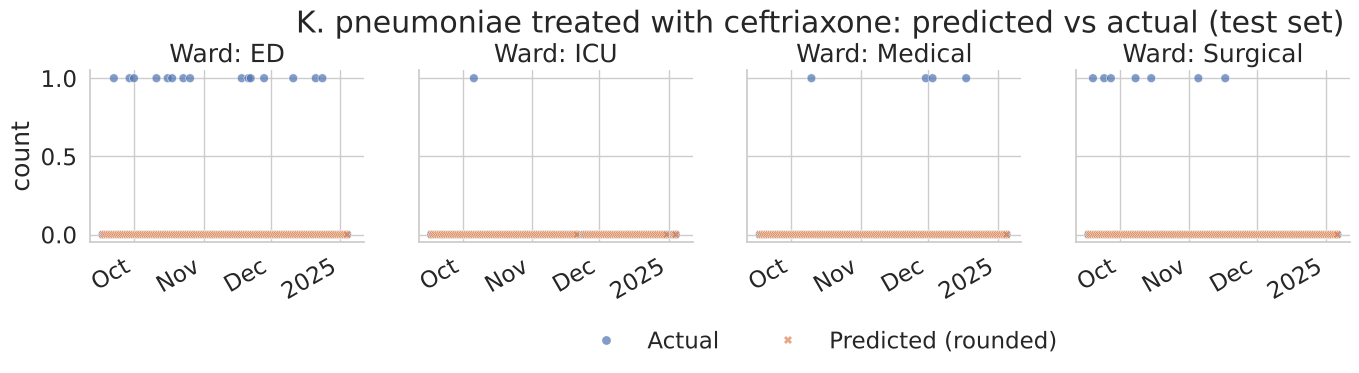

[K. pneumoniae treated with ceftriaxone] [K. pneumoniae treated with ceftriaxone (train)] Model 2: + device utilisation on test: MAE = 0.110, RMSE = 0.234 (n = 439)


In [21]:
result_largest = run_drug_bug_analysis(largest["organism"], largest["drug"], filename_prefix="largest_combo")



========== E. coli treated with ceftriaxone ==========
[E coli treated with ceftriaxone] 164 infections
[E. coli treated with ceftriaxone] attributed to exactly one ward: 140 of 164
  -> 24 detected after the last ward record (before discharge), given to the last ward stay
[E. coli treated with ceftriaxone] panel: 2,936 rows, 164 total infections in this panel
[E. coli treated with ceftriaxone] 515 train days (2057 ward-days), 110 validation days (440 ward-days), 112 test days (439 ward-days)

=== [E. coli treated with ceftriaxone (train)] Model 1: baseline only ===
     term      coef       se          z p_display sig      IRR  IRR_2.5%  IRR_97.5%
Intercept -6.091914 0.092848 -65.611937    <0.001 *** 0.002261  0.001885   0.002712
AIC = 822.82   deviance = 594.37   dispersion = 0.88

=== [E. coli treated with ceftriaxone (train)] Model 2: + device utilisation ===
              term      coef       se          z p_display sig      IRR  IRR_2.5%  IRR_97.5%
         Intercept -6.575804 

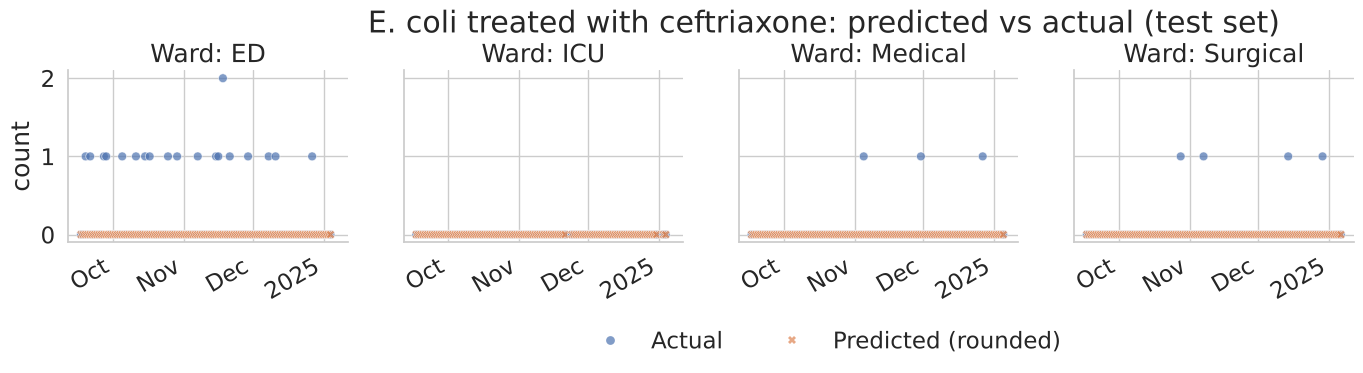

[E. coli treated with ceftriaxone] [E. coli treated with ceftriaxone (train)] Model 2: + device utilisation on test: MAE = 0.101, RMSE = 0.240 (n = 439)


In [22]:
result_ecoli_cef = run_drug_bug_analysis("E coli", "Ceftriaxone", filename_prefix="ecoli_ceftriaxone")

In [23]:
if result_largest is not None:
    result_largest["test_with_pred"].to_csv("largest_combo_panel_with_predictions.csv", index=False)
    result_largest["best"]["table"].to_csv("largest_combo_best_model_coefficients.csv", index=False)

if result_ecoli_cef is not None:
    result_ecoli_cef["test_with_pred"].to_csv("ecoli_ceftriaxone_panel_with_predictions.csv", index=False)
    result_ecoli_cef["best"]["table"].to_csv("ecoli_ceftriaxone_best_model_coefficients.csv", index=False)

print("Saved per-combination panel and coefficient CSVs")

Saved per-combination panel and coefficient CSVs


## Incidence rate ratios of the selected models (Table 4.4)

The intercept's IRR is the baseline rate per patient-day, shown here per 1,000 patient-days.

In [24]:
def irr_table(result_table, label):
    t = result_table[["term", "IRR", "IRR_2.5%", "IRR_97.5%", "p_display"]].copy()
    t.insert(0, "analysis", label)
    t["rate_per_1000"] = np.where(t["term"] == "Intercept", 1000 * t["IRR"], np.nan)
    return t

pd.concat([irr_table(best["table"], "All infections, Model 3"),
           irr_table(result_ecoli_cef["best"]["table"], f"{result_ecoli_cef['label']}, Model 2"),
           irr_table(result_largest["best"]["table"], f"{result_largest['label']}, Model 2")]).round(3)

,analysis,term,IRR,IRR_2.5%,IRR_97.5%,p_display,rate_per_1000
0,"All infections, Model 3",Intercept,0.022,0.019,0.026,<0.001,21.883
1,"All infections, Model 3",ICU,0.597,0.442,0.806,<0.001,NaN
2,"All infections, Model 3",Medical,0.955,0.824,1.106,0.537,NaN
3,"All infections, Model 3",Surgical,1.150,1.002,1.320,0.046,NaN
4,"All infections, Model 3",device_utilisation,2.264,1.297,3.951,0.004,NaN
0,"E. coli treated with ceftriaxone, Model 2",Intercept,0.001,0.001,0.002,<0.001,1.394
1,"E. coli treated with ceftriaxone, Model 2",device_utilisation,5.972,0.987,36.156,0.052,NaN
0,"K. pneumoniae treated with ceftriaxone, Model 2",Intercept,0.002,0.001,0.003,<0.001,2.074
1,"K. pneumoniae treated with ceftriaxone, Model 2",device_utilisation,2.580,0.466,14.281,0.278,NaN


## Negative binomial check

Each model is refitted as a negative binomial (variance = μ + αμ²; α = 0 is the Poisson model), with α estimated by profile likelihood on the training data. The likelihood-ratio p-value is halved because α = 0 lies on the boundary.

In [25]:
formulas = {"Model 1": "new_infections ~ 1",
            "Model 2": "new_infections ~ 1 + device_utilisation",
            "Model 3": "new_infections ~ 1 + device_utilisation + C(ward)"}

def nb_check(train_df, test_df, label):
    rows = []
    offset = np.log(train_df["n_at_risk"])
    for name, f in formulas.items():
        pois = smf.glm(f, data=train_df, family=sm.families.Poisson(), offset=offset).fit()
        grid = np.r_[1e-8, np.logspace(-5, 1, 121)]
        ll = np.array([smf.glm(f, data=train_df, family=sm.families.NegativeBinomial(alpha=a), offset=offset).fit().llf
                       for a in grid])
        alpha = grid[ll.argmax()]
        nb = smf.glm(f, data=train_df, family=sm.families.NegativeBinomial(alpha=alpha), offset=offset).fit()
        ci = grid[ll >= ll.max() - 1.92]                 # 95% profile-likelihood interval for alpha
        lr = max(0.0, 2 * (ll.max() - pois.llf))
        test_offset = np.log(test_df["n_at_risk"])
        row = dict(analysis=label, model=name, alpha=alpha, alpha_low=ci.min(), alpha_high=ci.max(),
                   AIC_poisson=pois.aic, AIC_nb=-2 * ll.max() + 2 * (len(nb.params) + 1),
                   p_LR=0.5 * chi2.sf(lr, 1) if lr > 1e-9 else 0.5,
                   test_MAE_poisson=(test_df["new_infections"] - pois.predict(test_df, offset=test_offset)).abs().mean(),
                   test_MAE_nb=(test_df["new_infections"] - nb.predict(test_df, offset=test_offset)).abs().mean())
        if "device_utilisation" in nb.params:
            row["IRR_device_poisson"] = np.exp(pois.params["device_utilisation"])
            row["IRR_device_nb"] = np.exp(nb.params["device_utilisation"])
        rows.append(row)
    return pd.DataFrame(rows)

pd.concat([nb_check(train_panel, test_panel, "All infections"),
           nb_check(result_ecoli_cef["train"], result_ecoli_cef["test"], result_ecoli_cef["label"]),
           nb_check(result_largest["train"], result_largest["test"], result_largest["label"])]).round(3)

,analysis,model,alpha,alpha_low,alpha_high,AIC_poisson,AIC_nb,p_LR,test_MAE_poisson,test_MAE_nb,IRR_device_poisson,IRR_device_nb
0,All infections,Model 1,0.000,0.0,0.035,3784.188,3786.189,0.500,0.588,0.588,NaN,NaN
1,All infections,Model 2,0.000,0.0,0.032,3776.665,3778.665,0.500,0.582,0.582,2.351,2.351
2,All infections,Model 3,0.000,0.0,0.032,3762.931,3764.931,0.500,0.572,0.572,2.264,2.264
0,E. coli treated with ceftriaxone,Model 1,0.000,0.0,0.794,822.824,824.824,0.500,0.103,0.103,NaN,NaN
1,E. coli treated with ceftriaxone,Model 2,0.000,0.0,0.708,821.206,823.206,0.500,0.101,0.101,5.972,5.972
2,E. coli treated with ceftriaxone,Model 3,0.000,0.0,0.708,822.764,824.765,0.500,0.101,0.101,6.572,6.572
0,K. pneumoniae treated with ceftriaxone,Model 1,0.316,0.0,1.413,958.736,960.143,0.221,0.111,0.111,NaN,NaN
1,K. pneumoniae treated with ceftriaxone,Model 2,0.316,0.0,1.413,959.577,960.980,0.220,0.110,0.110,2.580,2.609
2,K. pneumoniae treated with ceftriaxone,Model 3,0.282,0.0,1.259,959.180,960.676,0.239,0.111,0.111,2.815,2.840


## Device use and infection rates (Figure 4.3)

      inf  patient_days     lo     hi    rate
du_q                                         
Q1    154          6661  0.000  0.143  23.120
Q2    377         14259  0.143  0.215  26.439
Q3    527         19804  0.217  0.273  26.611
Q4    525         18886  0.273  0.333  27.798
Q5    417         13220  0.333  1.000  31.543


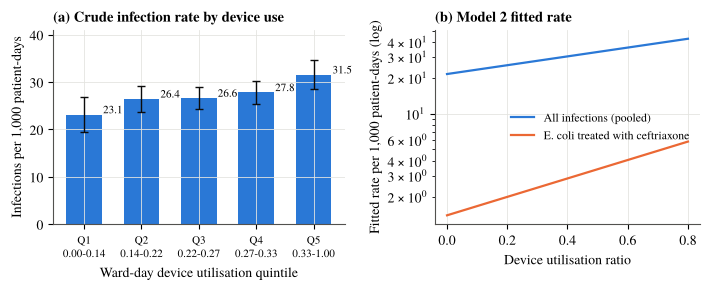

In [26]:
# Thesis figure style (matplotlib defaults plus a few changes, instead of the seaborn theme)
import matplotlib
THESIS_STYLE = {**{k: v for k, v in matplotlib.rcParamsDefault.items() if k != "backend"},
                "font.family": "serif", "font.serif": ["TeX Gyre Termes", "Times New Roman", "Liberation Serif"],
                "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10, "legend.fontsize": 8.5,
                "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e4e0",
                "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "axes.titleweight": "bold",
                "savefig.dpi": 300, "savefig.bbox": "tight", "lines.linewidth": 1.6, "axes.axisbelow": "line"}

# (a) Crude rate by quintile of ward-day device utilisation (all ward-days), 95% Poisson intervals
q = panel.assign(du_q=pd.qcut(panel["device_utilisation"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)]))
qg = q.groupby("du_q", observed=True).agg(inf=("new_infections", "sum"), patient_days=("n_at_risk", "sum"),
                                          lo=("device_utilisation", "min"), hi=("device_utilisation", "max"))
qg["rate"] = 1000 * qg["inf"] / qg["patient_days"]
se = 1000 * np.sqrt(qg["inf"]) / qg["patient_days"]
print(qg.round(3).to_string())

# (b) Model 2 fitted rate for all infections and for E. coli treated with ceftriaxone
b_all = fit_results["res2"]["model"].params
b_eco = result_ecoli_cef["best"]["model"].params
du = np.linspace(0, 0.8, 50)

with plt.rc_context(THESIS_STYLE):
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.0), gridspec_kw={"width_ratios": [1.1, 1]})
    ax[0].bar(range(5), qg["rate"], color="#2a78d6", width=0.62, yerr=1.96 * se,
              error_kw=dict(ecolor="#0b0b0b", lw=1, capsize=3))
    ax[0].set_xticks(range(5))
    ax[0].set_xticklabels([f"Q{i+1}\n{lo:.2f}-{hi:.2f}" for i, (lo, hi) in enumerate(zip(qg["lo"], qg["hi"]))], fontsize=8)
    ax[0].set_ylabel("Infections per 1,000 patient-days")
    ax[0].set_xlabel("Ward-day device utilisation quintile")
    ax[0].set_title("(a) Crude infection rate by device use", loc="left")
    ax[0].set_ylim(0, qg["rate"].max() * 1.3)
    for k, r in enumerate(qg["rate"]):
        ax[0].text(k + 0.33, r + 0.3, f"{r:.1f}", ha="left", fontsize=8)
    ax[1].plot(du, 1000 * np.exp(b_all["Intercept"] + b_all["device_utilisation"] * du), color="#2a78d6", label="All infections (pooled)")
    ax[1].plot(du, 1000 * np.exp(b_eco["Intercept"] + b_eco["device_utilisation"] * du), color="#eb6834", label="E. coli treated with ceftriaxone")
    ax[1].set_yscale("log")
    ax[1].set_xlabel("Device utilisation ratio")
    ax[1].set_ylabel("Fitted rate per 1,000 patient-days (log)")
    ax[1].set_title("(b) Model 2 fitted rate", loc="left")
    ax[1].legend(frameon=False, loc="center right")
    fig.tight_layout()
    fig.savefig("device_use_infection_rate.png")
    plt.show()

## Uncertainty in the Poisson forecasts (Figure 4.5)

(a) Predicted distribution for the test ward-day with the most infections. (b) 1,000 Poisson draws for each of the first 20 *E. coli* test ward-days, against the actual counts.

ED 2024-09-19: lambda = 1.85, actual = 6, P(Y >= 6) = 0.012


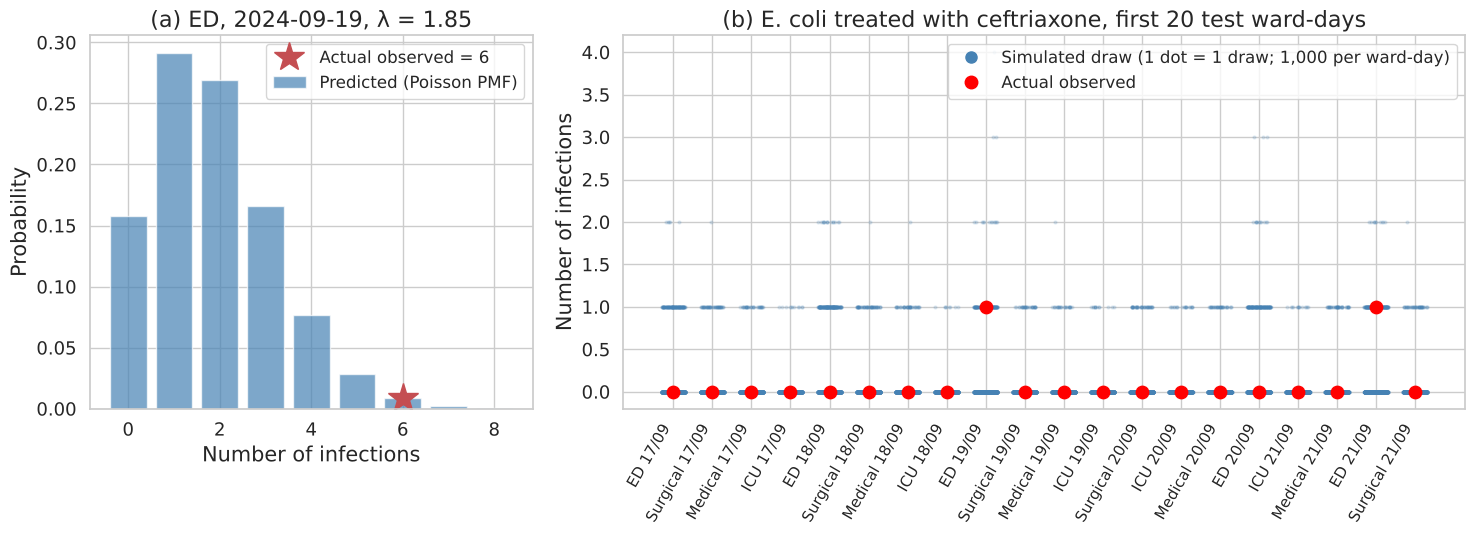

In [27]:
np.random.seed(123456)
N_DRAWS = 1000

row = test_with_predictions.loc[test_with_predictions["new_infections"].idxmax()]
lam, actual = row["predicted"], int(row["new_infections"])
draws = np.random.poisson(lam=lam, size=N_DRAWS)
k_values = np.arange(0, max(draws.max(), actual) + 2)
pmf_values = poisson.pmf(k_values, mu=lam)
print(f"{row['ward']} {row['date'].date()}: lambda = {lam:.2f}, actual = {actual}, P(Y >= {actual}) = {poisson.sf(actual - 1, lam):.3f}")

combo_df = result_ecoli_cef["test_with_pred"].sort_values("date").reset_index(drop=True).head(20)
sim_rows = []
for i, r in combo_df.iterrows():
    day_draws = np.random.poisson(lam=r["predicted"], size=N_DRAWS)
    jitter_x = i + np.random.uniform(-0.3, 0.3, size=N_DRAWS)
    sim_rows.append(pd.DataFrame({"x": jitter_x, "y": day_draws}))
sim_df = pd.concat(sim_rows, ignore_index=True)

with plt.rc_context(BIG_FONTS):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.9]})
    ax = axes[0]
    ax.bar(k_values, pmf_values, color="steelblue", alpha=0.7, label="Predicted (Poisson PMF)")
    ax.plot(actual, pmf_values[actual], "r*", markersize=22, label=f"Actual observed = {actual}")
    ax.set_xlabel("Number of infections")
    ax.set_ylabel("Probability")
    ax.set_title(f"(a) {row['ward']}, {row['date'].date()}, λ = {lam:.2f}")
    ax.legend(fontsize=12)
    ax = axes[1]
    ax.scatter(sim_df["x"], sim_df["y"], s=4, alpha=0.15, color="steelblue")
    ax.scatter(range(len(combo_df)), combo_df["new_infections"], color="red", s=80, zorder=5)
    ax.set_xticks(range(len(combo_df)))
    ax.set_xticklabels([f"{w} {d:%d/%m}" for d, w in zip(combo_df["date"], combo_df["ward"])], rotation=60, ha="right", fontsize=11)
    ax.set_ylabel("Number of infections")
    ax.set_title("(b) E. coli treated with ceftriaxone, first 20 test ward-days")
    # legend markers drawn larger and darker than the faint plotted dots so they are easy to see
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color="steelblue", markersize=8,
                              label="Simulated draw (1 dot = 1 draw; 1,000 per ward-day)"),
                       Line2D([], [], marker="o", ls="", color="red", markersize=9, label="Actual observed")], fontsize=12)
    plt.tight_layout()
    plt.savefig("poisson_uncertainty.png", dpi=150)
    plt.show()

## Goodness of fit on the test set (Figure 4.6)

Observed number of test ward-days with 0, 1, 2, ... infections against the number expected from the predicted Poisson distributions.

(a) All infections, Model 3 | observed: [267, 97, 37, 26, 10, 1, 1, 0, 0] | expected: [266.8, 103.6, 42.3, 17.2, 6.4, 2.0, 0.6, 0.1, 0.0]
(b) E. coli treated with ceftriaxone, Model 2 | observed: [413, 25, 1, 0] | expected: [417.0, 20.9, 1.0, 0.0]


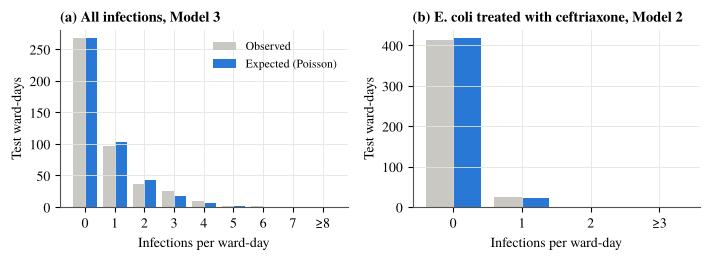

In [28]:
with plt.rc_context(THESIS_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
    for ax, (df, title, K) in zip(axes, [(test_with_predictions, "(a) All infections, Model 3", 8),
                                         (result_ecoli_cef["test_with_pred"], "(b) E. coli treated with ceftriaxone, Model 2", 3)]):
        k = np.arange(0, K + 1)
        expected = np.array([poisson.pmf(kk, df["predicted"]).sum() for kk in k])
        expected[-1] = len(df) - expected[:-1].sum()                 # last bar = K or more
        observed = np.array([(df["new_infections"] == kk).sum() for kk in k[:-1]] + [(df["new_infections"] >= K).sum()])
        ax.bar(k - 0.2, observed, width=0.4, color="#c9c8c2", label="Observed")
        ax.bar(k + 0.2, expected, width=0.4, color="#2a78d6", label="Expected (Poisson)")
        ax.set_xticks(k)
        ax.set_xticklabels([str(x) for x in k[:-1]] + [f"≥{K}"])
        ax.set_xlabel("Infections per ward-day")
        ax.set_ylabel("Test ward-days")
        ax.set_title(title, loc="left")
        print(title, "| observed:", observed.tolist(), "| expected:", expected.round(1).tolist())
    axes[0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig("goodness_of_fit.png")
    plt.show()